In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix

In [3]:
# 1.	Load the Iris dataset and display the first five rows, shape, and feature names of the dataset.
df = pd.read_csv('/content/Iris.csv')
print("First five rows:")
print(df.head())

First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [8]:
print("Shape:")
df.shape

Shape:


(150, 6)

In [7]:
print("Feature names:")
print(df.columns.tolist())

Feature names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [9]:
# 2.    Standardize the feature columns using StandardScaler() and display the transformed data.
scaler = StandardScaler()
feature_columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
scaled_features = scaler.fit_transform(df[feature_columns])

scaled_df = pd.DataFrame(scaled_features, columns=feature_columns)
print("\nTransformed data (first five rows):")
display(scaled_df.head())


Transformed data (first five rows):


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


In [10]:
# 3. Apply K-Means clustering with n_clusters = 3 and add the predicted cluster labels to the dataset
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(scaled_features)

print("\nDataset with cluster labels (first five rows):")
display(df.head())


Dataset with cluster labels (first five rows):


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,1
2,3,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5,5.0,3.6,1.4,0.2,Iris-setosa,1


In [ ]:
#

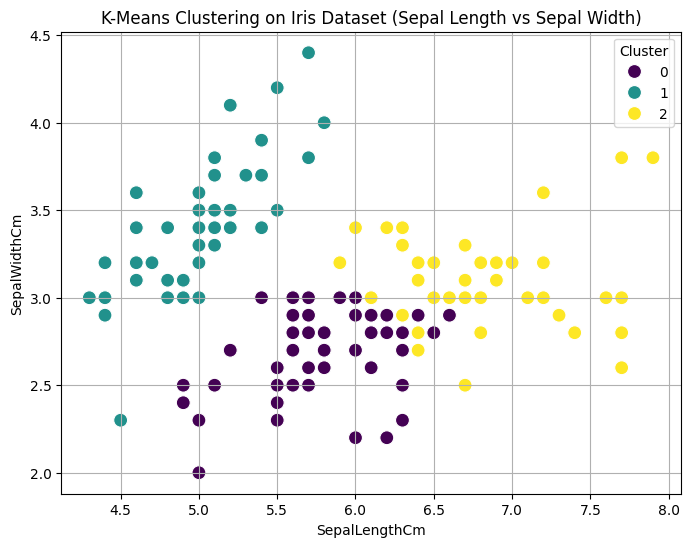

In [11]:
# 4. Plot a scatter plot for SepalLength vs SepalWidth using the cluster labels as color (hue).
plt.figure(figsize=(8, 6))
sns.scatterplot(x='SepalLengthCm', y='SepalWidthCm', hue='Cluster', data=df, palette='viridis', s=100)
plt.title('K-Means Clustering on Iris Dataset (Sepal Length vs Sepal Width)')
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

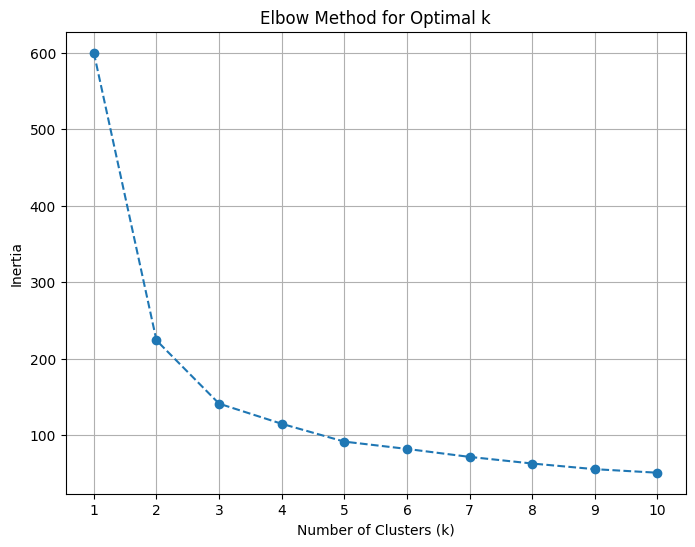

In [12]:
# 5. Use the Elbow Method to find the optimal number of clusters by plotting inertia values for k = 1 to 10.
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

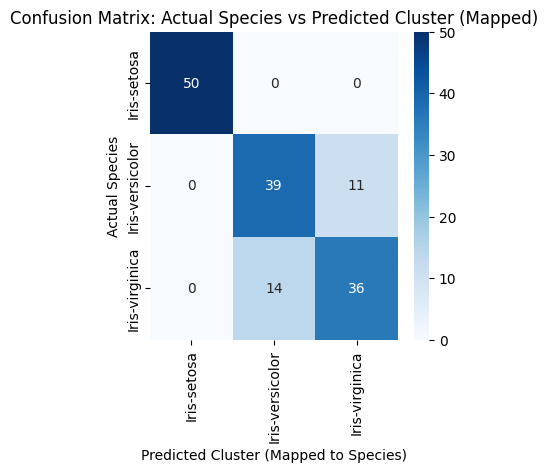

In [19]:
# 6. Compare the predicted cluster labels with the actual species and display the confusion matrix.

cluster_species_mapping = {}
for cluster in df['Cluster'].unique():
    species_in_cluster = df[df['Cluster'] == cluster]['Species']

    most_frequent_species = species_in_cluster.mode()[0]
    cluster_species_mapping[cluster] = most_frequent_species

df['Predicted_Species'] = df['Cluster'].map(cluster_species_mapping)

conf_matrix = confusion_matrix(df['Species'], df['Predicted_Species'])

plt.figure(figsize=(4, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=df['Species'].unique(), yticklabels=df['Species'].unique())
plt.title('Confusion Matrix: Actual Species vs Predicted Cluster (Mapped)')
plt.xlabel('Predicted Cluster (Mapped to Species)')
plt.ylabel('Actual Species')
plt.show()

In [20]:
# 1. Load the Iris dataset, extract only the feature columns, and standardize them using StandardScaler().
df = pd.read_csv('/content/Iris.csv')
feature_columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
features_df = df[feature_columns]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_df)

print("Scaled features (first five rows):")
display(pd.DataFrame(scaled_features, columns=feature_columns).head())

Scaled features (first five rows):


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


In [21]:
# 2. Apply DBSCAN clustering with eps = 0.8 and min_samples = 5 and print the cluster labels assigned.
from sklearn.cluster import DBSCAN

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=0.8, min_samples=5)
dbscan_labels = dbscan.fit_predict(scaled_features)

# Print the cluster labels
print("DBSCAN Cluster Labels:")
print(dbscan_labels)

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


In [22]:
# 3. Count the total number of clusters formed and the number of noise points (label = -1).
unique_labels, counts = np.unique(dbscan_labels, return_counts=True)

n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

n_noise = counts[unique_labels == -1][0] if -1 in unique_labels else 0

print(f"Total number of clusters formed: {n_clusters}")
print(f"Number of noise points (label = -1): {n_noise}")

Total number of clusters formed: 2
Number of noise points (label = -1): 4


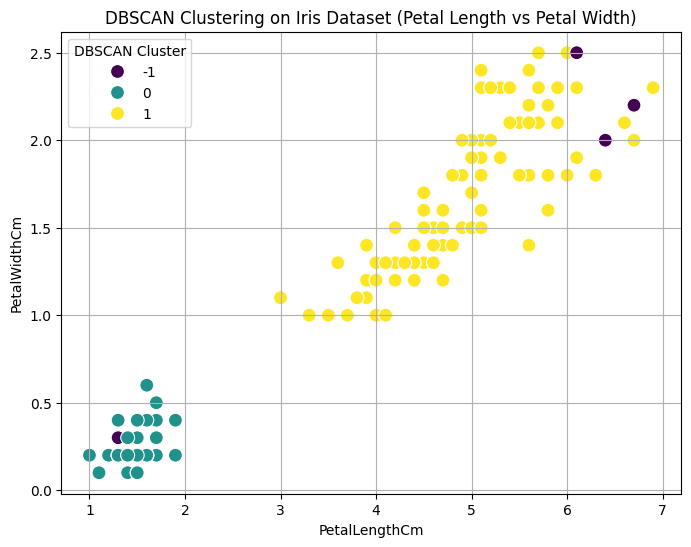

In [23]:
# 4. Plot a scatter plot for PetalLength vs PetalWidth showing the DBSCAN cluster assignments.
df['DBSCAN_Cluster'] = dbscan_labels

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PetalLengthCm', y='PetalWidthCm', hue='DBSCAN_Cluster', data=df, palette='viridis', s=100)
plt.title('DBSCAN Clustering on Iris Dataset (Petal Length vs Petal Width)')
plt.xlabel('PetalLengthCm')
plt.ylabel('PetalWidthCm')
plt.legend(title='DBSCAN Cluster')
plt.grid(True)
plt.show()

In [24]:
# 5. Experiment with different values of eps (e.g., 0.3, 0.5, 0.8) and observe how the number of clusters changes.
eps_values = [0.3, 0.5, 0.8]
min_samples = 5

print("Experimenting with different eps values for DBSCAN:")

for eps in eps_values:
    print(f"\n--- Running DBSCAN with eps = {eps} and min_samples = {min_samples} ---")
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    dbscan_labels = dbscan.fit_predict(scaled_features)

    unique_labels, counts = np.unique(dbscan_labels, return_counts=True)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
    n_noise = counts[unique_labels == -1][0] if -1 in unique_labels else 0

    print(f"Total number of clusters formed: {n_clusters}")
    print(f"Number of noise points (label = -1): {n_noise}")

Experimenting with different eps values for DBSCAN:

--- Running DBSCAN with eps = 0.3 and min_samples = 5 ---
Total number of clusters formed: 3
Number of noise points (label = -1): 120

--- Running DBSCAN with eps = 0.5 and min_samples = 5 ---
Total number of clusters formed: 2
Number of noise points (label = -1): 35

--- Running DBSCAN with eps = 0.8 and min_samples = 5 ---
Total number of clusters formed: 2
Number of noise points (label = -1): 4


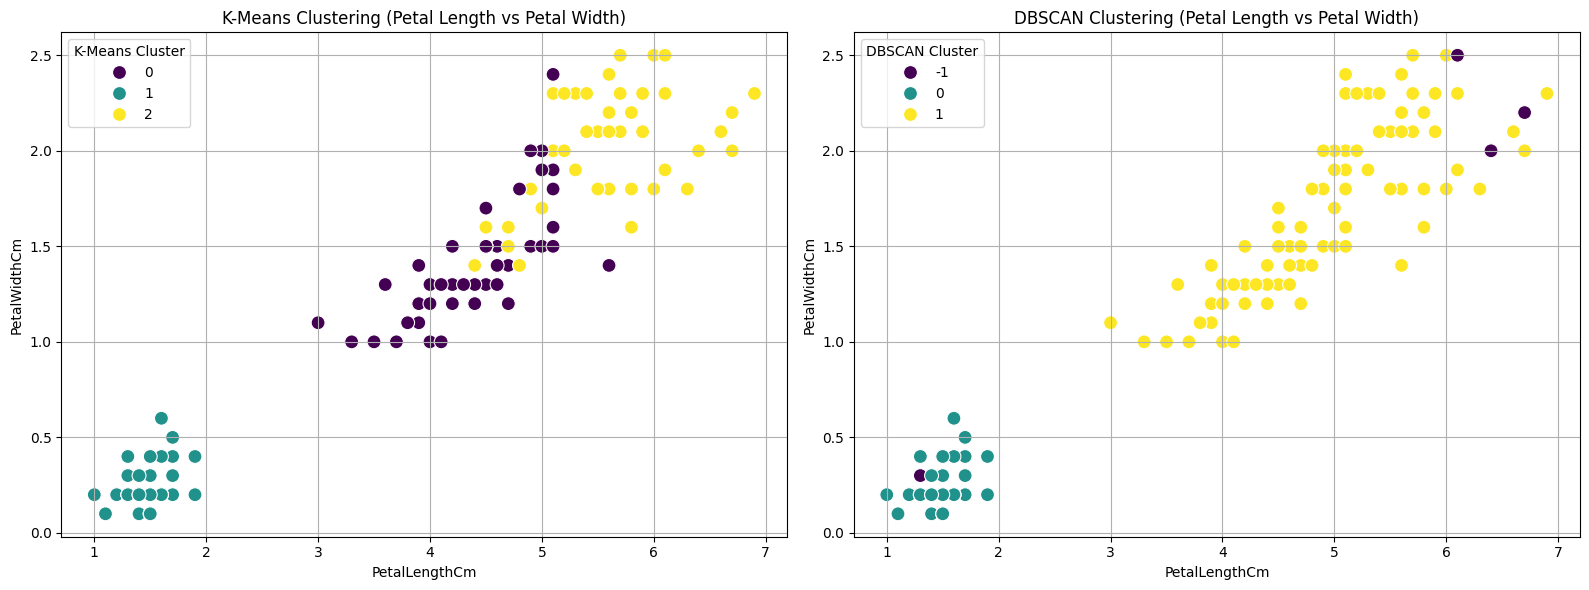

In [27]:
# Visualize K-Means and DBSCAN results side-by-side for comparison
if 'Cluster' not in df.columns:
    print("Running K-Means clustering to generate 'Cluster' column...")
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    df['Cluster'] = kmeans.fit_predict(scaled_features)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means scatter plot
sns.scatterplot(x='PetalLengthCm', y='PetalWidthCm', hue='Cluster', data=df, palette='viridis', s=100, ax=axes[0])
axes[0].set_title('K-Means Clustering (Petal Length vs Petal Width)')
axes[0].set_xlabel('PetalLengthCm')
axes[0].set_ylabel('PetalWidthCm')
axes[0].legend(title='K-Means Cluster')
axes[0].grid(True)

# DBSCAN scatter plot
sns.scatterplot(x='PetalLengthCm', y='PetalWidthCm', hue='DBSCAN_Cluster', data=df, palette='viridis', s=100, ax=axes[1])
axes[1].set_title('DBSCAN Clustering (Petal Length vs Petal Width)')
axes[1].set_xlabel('PetalLengthCm')
axes[1].set_ylabel('PetalWidthCm')
axes[1].legend(title='DBSCAN Cluster')
axes[1].grid(True)

plt.tight_layout()
plt.show()